In [1]:
import strahler
import bz2
from importlib.metadata import version as package_version

package = package_version("strahler")
library = strahler.version()
if package != library:
    raise RuntimeError("Package/library version mismatch. Reinstall strahler in this kernel, "
                       "check STRAHLER_LIB, and restart the kernel before continuing.")
print("strahler package and library versions match")

from notebook_support import HERE, table, decomposition_views
from IPython.display import HTML, Markdown, SVG, display
from strahler.widgets import TreeView
from lexicographic_nester import BACKENDS, manifest, host_svg, recorded_final_results

strahler package and library versions match


# Nester: keep the Strahler bound small

Adaptive walks `(k,t)` lexicographically: exhaust `t` at one `k`, then
increase `k` and reset `t` to zero. We run AD lifting and Strahler
progress-measure lifting (PM), each with and without iterative shaving
(`+iter`), on the noncompact Nester family.
Preprocessing and same-parity priority compression are off.

In [2]:
games = manifest()
reference = recorded_final_results()
first = {row["backend"]: row for row in reference["rows"] if row["n"] == 1}
nester1 = games[0]
assert nester1["vertices"] == 22

## Host trees

A host supplies the positions available to the solver. We write it as $U^k_{t,h}$:

| Parameter | Meaning |
|---|---|
| $k$ | Allowed Strahler number; a chain has number 1. |
| $t$ | Size allowance; increasing it makes room for more leaves. |
| $h$ | Number of node levels, including the root. |

Each player has its own host. PM reads the $h-1$ edges along a root-to-leaf
path as the components of a measure.

These are the complete hosts at Nester-1's first successful pairs.
Left-hand numbers are depths, starting at zero for the root. Edge labels are bitstrings;
$\varepsilon$ is the empty string.

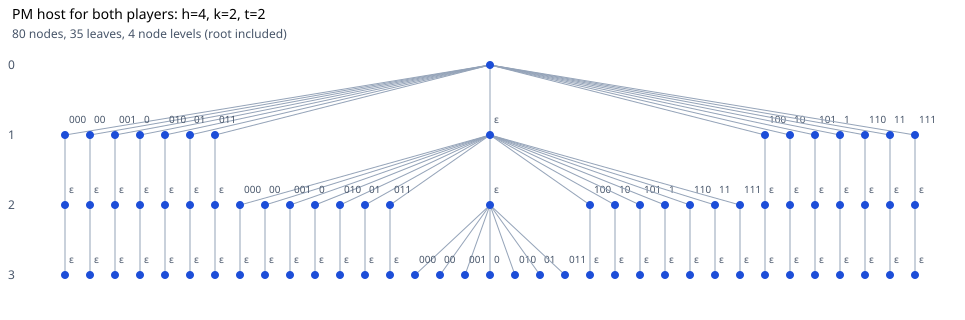

In [3]:
# AD reports H -> h, K -> k, and t -> t.
ad_hosts = []
for player, parameters in zip(("Even", "Odd"), first["AD"]["parameters"]):
    h, k, t = (parameters[key] for key in ("H", "K", "t"))
    # host_svg takes (k, t, height), with height=h, to draw U^k_{t,h}.
    ad_hosts.append(host_svg(k, t, h, f"AD host for {player}: h={h}, k={k}, t={t}"))
display(HTML('<div style="display:flex;flex-wrap:wrap;gap:12px">' + "".join(ad_hosts) + '</div>'))

# PM reports depth -> h-1, k -> k, and t -> t.
pm_parameters = first["PM"]["parameters"]
assert pm_parameters[0] == pm_parameters[1]
h = pm_parameters[0]["depth"] + 1
k, t = (pm_parameters[0][key] for key in ("k", "t"))
display(SVG(host_svg(k, t, h, f"PM host for both players: h={h}, k={k}, t={t}")))

AD solves Nester-1 with a chain, `(k,t)=(1,0)`. PM uses `(k,t)=(2,2)`,
whose host has 35 leaves for 22 vertices. Shaving gives the same pairs here.

## Lazy positions in AD

AD labels each vertex with a host position, using normalized priorities.
A regular node of priority level $r$
accepts priority $r$. A lazy position is an extra label between regular
nodes, accepting priorities up to its level.

At a finite lazy label $\ell$, the player's strategy must force a strictly
earlier label while staying at $\ell$ or earlier. Several moves may share
the lazy label. With labelling $\mu$, the target is $\{v:\mu(v)<\ell\}$ and
the safe set is $\{v:\mu(v)\leq\ell\}$. Earlier follows the host's depth-first
order. Failed reachability lifts the vertex to a later compatible label
[Jurdziński et al. '20, §2.1] ([arXiv](https://arxiv.org/html/2010.08288)).

Regular and lazy positions correspond to decomposition blocks:

| Position | Place in the order | Block |
|---|---|---|
| Regular $\eta$ | Base-host node | H (blue): vertices at its priority |
| Lazy $-\infty(\eta)$ | After $\eta$, before its children | T (green): additional vertices attracted to H |
| Lazy $c^+$ | After child $c$'s subtree | S (orange) of $c$: vertices the parent attracts into that subtree |

At level $r$, the $-\infty$ and child-after slots have level $r-1$.
TOP, after the whole host, holds vertices outside the player's certified region.
See the [implementation notes](../docs/developing.md#attractor-decomposition-lifting) for the ordering.

In Nester-1, vertex 16 has only the move `16 → 17`: 16 is in T and 17 in H,
so its lazy label reaches an earlier regular label in one move.

## Nester-1's answer trees

The 22 vertices fit in the block view. AD and AD+iter return the same
decomposition: Even wins all 22; Odd's tree is empty.

In Jupyter, hover links the two views. Node names `ε, ε1, ε11, ε111` match the block superscripts.
Tree nodes show normalized priority bounds;
block shapes contain original priorities, with vertex IDs underneath.
Squares belong to Even, pentagons to Odd.

PM+iter's final tree covers the vertices left after earlier shaving rounds.

AD and AD+iter: Even's decomposition.

Static widget snapshot; rerun for interactive controls.

PM: Even's occupied tree at the final pair.

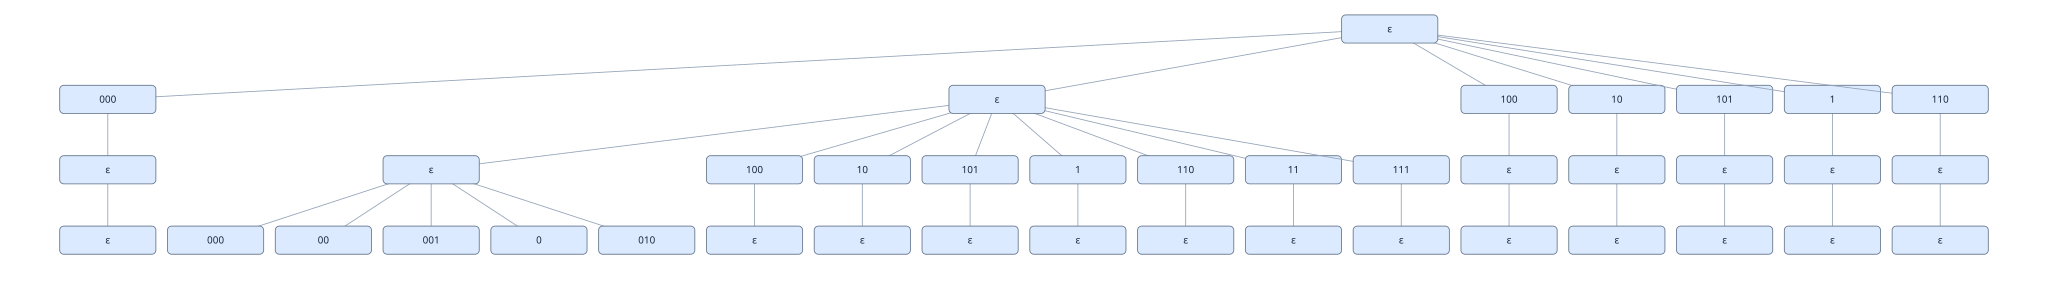

PM+iter: Even's occupied tree at the final pair.

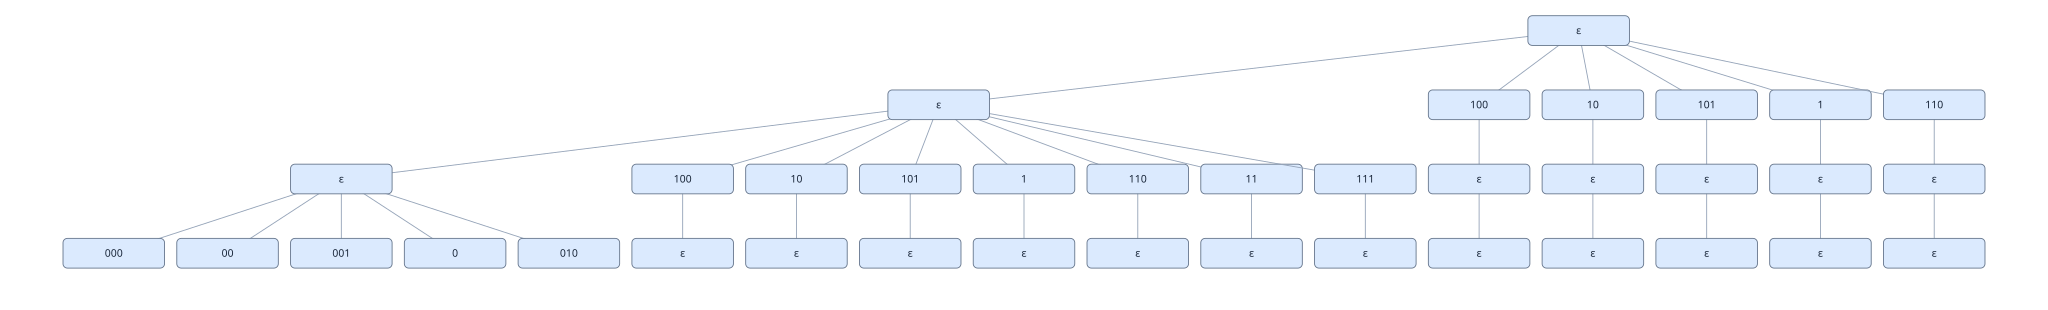

In [4]:
def label_priorities(node, path=()):
    if node is None:
        return None
    name = "ε" + "".join(str(i + 1) for i in path)
    # AD node["h"] is a priority bound; the host height h counts levels.
    return dict(node, label=f"{name}: bound {node['h']}",
                children=[label_priorities(child, path + (i,))
                          for i, child in enumerate(node['children'])])

nester_game = strahler.Game.from_text(
    bz2.open(HERE / "nester" / nester1["file"], "rt").read())
ad_example = first["AD"]["example"]
assert ad_example["trees"] == first["AD+iter"]["example"]["trees"]
assert strahler.check(nester_game, ad_example["trees"][0], 0).ok
ad_tree = label_priorities(ad_example["trees"][0])
assert nester_game.successors[16] == (17,)
assert 16 in ad_tree["children"][0]["T"] and 17 in ad_tree["children"][0]["H"]
display(Markdown("AD and AD+iter: Even's decomposition."))
ordered_ad, blocks_ad = decomposition_views(ad_tree, nester_game)

for backend in ("PM", "PM+iter"):
    tree = first[backend]["example"]["rounds"][-1]["trees"][0]["tree"]
    display(Markdown(f"{backend}: Even's occupied tree at the final pair."))
    display(TreeView(tree, mode="tree", edges=False))

## Caps and search order

Let $N$ count game vertices and $h$ count host levels, including the root.
A certificate has at most $N$ occupied leaves. Proposition 3 and Lemma 16
[Daviaud et al. '20] ([arXiv](https://arxiv.org/html/2003.08627)) give

$$t_{\max}=\lfloor\log_2 N\rfloor,\qquad
k_{\max}=\min(h,t_{\max}+1).$$

The extra 1 comes from a single node having Strahler number 1.
At $t_{\max}$ the host accommodates every certificate with these bounds;
the host itself may have more than $N$ leaves.
Theorem 26 [Daviaud et al. '20] ([arXiv](https://arxiv.org/html/2003.08627))
gives the same leaf bound for PM. E/O means Even/Odd.

In [5]:
def eo(values):
    return " / ".join(map(str, values))

# Manifest mapping: AD_height is h, PM_depth+1 is h; both *_k_max fields cap k.
table(["Nester n", "vertices N", "t cap", "AD h E/O", "PM h E/O",
       "AD k cap E/O", "PM k cap E/O"],
      [[g["n"], g["vertices"], g["t_max"], eo(g["AD_height"]),
        eo([d + 1 for d in g["PM_depth"]]), eo(g["AD_k_max"]), eo(g["PM_k_max"])]
       for g in games])

Nester n,vertices N,t cap,AD h E/O,PM h E/O,AD k cap E/O,PM k cap E/O
1,22,4,4 / 3,4 / 4,4 / 3,4 / 4
2,365,8,6 / 5,6 / 6,6 / 5,6 / 6
3,3029,11,8 / 7,8 / 8,8 / 7,8 / 8
4,14053,13,9 / 8,9 / 9,9 / 8,9 / 9
5,62707,15,10 / 9,10 / 10,10 / 9,10 / 10
6,259455,17,11 / 10,11 / 11,11 / 10,11 / 11
7,1021740,19,12 / 11,12 / 12,12 / 11,12 / 12


Nester-1 has $t_{\max}=4$: `(1,0), …, (1,4), (2,0), (2,1), …`.
Each player's `k` is capped by its height. The first complete answer stops
the walk.

Without `+iter`, every pair starts on the whole game. With `+iter`, wins
and their attractors leave before the next pair; the initial caps stay fixed.
AD computes both players' regions before removal. PM removes Even's region
before solving for Odd. Each attempt starts at the lowest compatible labels.
Both APIs use `search="lexicographic"`.

## Results: five minutes per case

Runs have a 300-second total budget and a 2 GiB address-space
limit on Linux. The machine has four CPUs; at most two solvers run together.
AD has no separate leaf-count cutoff.

Cells show the first successful `(k,t)` and elapsed seconds, or `300 s limit`.

All four methods time out on Nester-5. We stop there; Nester-6–7 are marked
beyond this frontier.

In [6]:
by_case = {(r["n"], r["backend"]): r for r in reference["rows"]}

def result_text(row):
    if row["outcome"] == "complete":
        return f"({row['k']},{row['t']}), {row['seconds']:.2f} s"
    if row["outcome"] == "not measured":
        return "beyond frontier"
    return "300 s limit" if row["outcome"] == "timeout" else row["outcome"]

table(["Nester n", "vertices N", *BACKENDS],
      [[g["n"], g["vertices"], *[result_text(by_case[g["n"], b]) for b in BACKENDS]]
       for g in games])

largest = [max((r for r in reference["rows"]
                if r["backend"] == b and r["outcome"] == "complete"), key=lambda r: r["n"])
           for b in BACKENDS]
display(Markdown("Largest solved instance for each method:"))
table(["method", "Nester n", "first (k,t)", "final tree Strahler E/O", "total wins E/O"],
      [[r["backend"], r["n"], (r["k"], r["t"]), eo(r["tree_strahler"]), eo(r["won"])]
       for r in largest])

Nester n,vertices N,AD,AD+iter,AD-sym,AD-sym+iter,PM,PM+iter
1,22,"(1,0), 0.18 s","(1,0), 0.18 s","(1,0), 0.22 s","(1,0), 0.23 s","(2,2), 0.18 s","(2,2), 0.18 s"
2,365,"(2,1), 0.28 s","(1,1), 0.19 s","(2,1), 0.23 s","(1,1), 0.22 s","(3,2), 0.30 s","(3,2), 0.24 s"
3,3029,"(2,1), 3.50 s","(2,1), 2.17 s","(2,1), 1.47 s","(2,1), 0.70 s","(4,3), 242.70 s","(4,3), 59.67 s"
4,14053,300 s limit,"(2,2), 31.35 s",300 s limit,"(2,2), 9.45 s",300 s limit,300 s limit
5,62707,300 s limit,300 s limit,300 s limit,300 s limit,300 s limit,300 s limit
6,259455,beyond frontier,beyond frontier,beyond frontier,beyond frontier,beyond frontier,beyond frontier
7,1021740,beyond frontier,beyond frontier,beyond frontier,beyond frontier,beyond frontier,beyond frontier


Largest solved instance for each method:

method,Nester n,"first (k,t)",final tree Strahler E/O,total wins E/O
AD,3,"(2, 1)",2 / 1,1993 / 1036
AD+iter,4,"(2, 2)",2 / 0,7868 / 6185
AD-sym,3,"(2, 1)",2 / 1,1993 / 1036
AD-sym+iter,4,"(2, 2)",2 / 0,7868 / 6185
PM,3,"(4, 3)",4 / 2,1993 / 1036
PM+iter,3,"(4, 3)",4 / 0,1993 / 1036


`Total wins` includes earlier shaving rounds and their attractors.
`Final tree Strahler` measures the last occupied tree; shaving retains
certificates from earlier rounds.

On Nester-2, AD finishes at `(2,1)` on the whole game and `(1,1)` with
shaving, which combines certificates from different rounds.

## Sources

The games are MLSolver validity games from the [Parity games dataset](https://doi.org/10.6084/m9.figshare.6004130.v1)
[Keiren '18], under CC0. Its archive contains n=1…7; the requested n=8 is absent.
Original files and checksums are bundled in `nester/`.

Host bounds: *The Strahler Number of a Parity Game* [Daviaud et al. '20]
([arXiv](https://arxiv.org/abs/2003.08627)). Lazy positions:
*A symmetric attractor-decomposition lifting algorithm for parity games*
[Jurdziński et al. '20] ([arXiv](https://arxiv.org/abs/2010.08288)).

[Recorded results](nester/lexicographic-results-300s.json) ·
[Experiment helper](lexicographic_nester.py).